# Stat 220 Midterm B: the take-home analysis
## Turnaround time at a bicycle repair shop

A repair shop switched to a new parts supplier for some jobs this year. The owner compared average turnaround before and after, saw no real difference, and is about to go back to the old supplier. They have asked you to check.

**100 points in all.** Run the setup cell first. Put your work in the cell under each task and your written answer in the markdown cell that follows it. Several tasks build on an earlier one, so work them in order.

---

**Getting help.** You may use AI, and you may ask the TAs, the professor, and each other. Two limits on the AI:

- Do not paste the whole notebook into it.
- Do not give it an entire task prompt and ask for the answer. If a prompt is unclear, you can paste a whole task prompt in to help clarify.

Everything else is open. Use the generate function in Colab or your editor to help write the code, ask about a specific piece of output, or have a piece of your work checked.

Use the methods from this course. A technique we have not covered is a sign that the AI has been asked for the answer rather than for help.

Add text or code boxes as needed, but do not change or modify the numbering of the tasks.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split
from statsmodels.stats.anova import anova_lm

repairs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/repair_jobs.csv")
repairs.head()

,days,parts_needed,parts_cost,tech_years,bike_type,new_supplier,ticket_number,shop_rating,quarter
0,4.32,5,86.03,1,mountain,0,2833,2,2
1,1.24,1,21.65,1,electric,0,2590,2,2
2,8.57,5,99.39,2,electric,1,5472,1,2
3,1.23,0,0.00,5,road,0,6510,5,3
4,0.72,2,38.79,2,commuter,0,3206,2,3


### Task 1.  (6 points)

Before you fit anything, decide what kind of model this question calls for. Name the family, say why it suits this outcome, and say what you need back from it that a random forest could not give you.

I would use multiple linear regression because the outcome, repair days, is a continuous numeric variable. I need coefficients, p-values, and confidence intervals to measure and interpret the supplier’s effect on repair time while accounting for other predictors, which a random forest does not directly provide.


### Task 2.  (8 points)

Make two plots that could be helpful concerning the shop's question. Then, in two or three sentences, say if there is anything notable you see that may affect modeling choices.

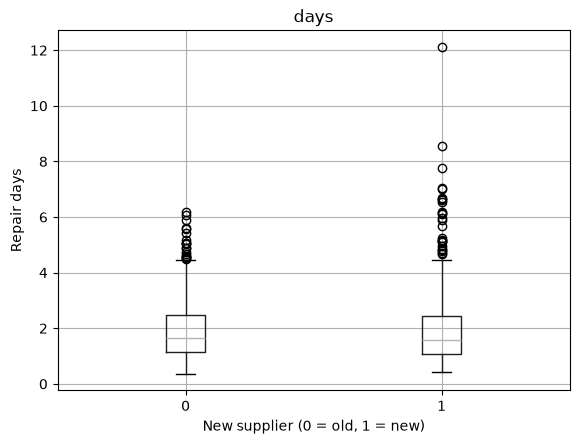

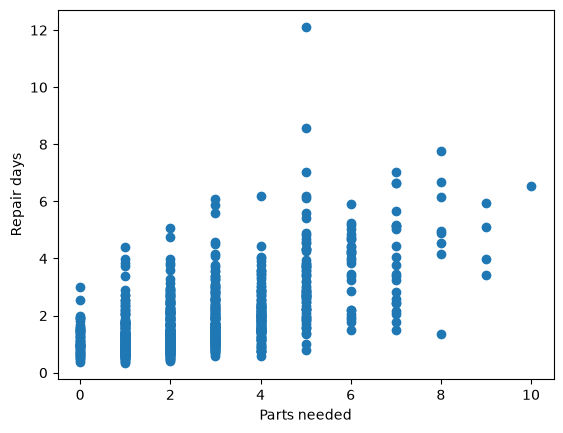

In [14]:
repairs.boxplot(column="days", by="new_supplier")
plt.suptitle("")
plt.xlabel("New supplier (0 = old, 1 = new)")
plt.ylabel("Repair days")
plt.show()

plt.scatter(repairs["parts_needed"], repairs["days"])
plt.xlabel("Parts needed")
plt.ylabel("Repair days")
plt.show()

The repair times for the old and new suppliers have similar centers, but the new supplier has more variability and some unusually long repair times. Repair time generally increases as more parts are needed, and the relationship appears nonlinear, so the model should account for job size and possible differences in variability.


### Task 3.  (10 points)

The owner compared average repair time under the old and the new supplier, saw almost no difference, and is ready to drop the new one. Perform a formal statistical test for that comparison. Report both averages, the difference, a test, and a 95% interval, then say in two or three sentences what it does and does not establish.

In [15]:
old = repairs.loc[repairs["new_supplier"] == 0, "days"]
new = repairs.loc[repairs["new_supplier"] == 1, "days"]

result = stats.ttest_ind(new, old, equal_var=False)

difference = new.mean() - old.mean()

se = np.sqrt(
    new.var(ddof=1) / len(new)
    + old.var(ddof=1) / len(old)
)

df = (
    (new.var(ddof=1) / len(new) + old.var(ddof=1) / len(old)) ** 2
    /
    (
        (new.var(ddof=1) / len(new)) ** 2 / (len(new) - 1)
        + (old.var(ddof=1) / len(old)) ** 2 / (len(old) - 1)
    )
)

margin = stats.t.ppf(0.975, df) * se

print("Old supplier mean:", old.mean())
print("New supplier mean:", new.mean())
print("Difference:", difference)
print("t-statistic:", result.statistic)
print("p-value:", result.pvalue)
print("95% CI:", (difference - margin, difference + margin))

Old supplier mean: 1.9371820448877803
New supplier mean: 2.0159899749373436
Difference: 0.07880793004956321
t-statistic: 0.8515614542586756
p-value: 0.3947291653399474
95% CI: (np.float64(-0.10287032495236867), np.float64(0.2604861850514951))


The new supplier's average repair time was 2.016 days, compared with 1.937 days for the old supplier, a difference of about 0.079 days. The Welch \(t\)-test gives a p-value of 0.395, and the 95% confidence interval includes zero, so there is not statistically significant evidence of a difference in mean repair time. However, this does not establish that the suppliers perform equally; the data remain compatible with the new supplier being somewhat faster or slower.


### Task 4.  (8 points)

Now fit a model for repair time that includes the supplier indicator along with `parts_needed`, `tech_years` and `bike_type`. Report the supplier coefficient with its interval, interpret it in a sentence that names what is held fixed, and explain in two or three sentences why it differs from Task 3.

In [16]:
fit = smf.ols(
    "days ~ new_supplier + parts_needed + tech_years + C(bike_type)",
    data=repairs
).fit()

print(fit.params.round(3))
print("\n95% interval for supplier:")
print(fit.conf_int().loc["new_supplier"].round(3).tolist())

Intercept                   0.992
C(bike_type)[T.electric]    0.746
C(bike_type)[T.mountain]    0.147
C(bike_type)[T.road]       -0.098
new_supplier               -0.428
parts_needed                0.467
tech_years                 -0.068
dtype: float64

95% interval for supplier:
[-0.573, -0.282]


The coefficient for the new supplier is −0.428 days (95% CI: −0.573 to −0.282), meaning repairs take an estimated 0.428 fewer days on average, holding the other predictors constant.

In Task 3, we compared the raw averages without accounting for differences in repair jobs. Task 4 controls for parts needed, technician experience, and bike type, which can affect repair time. Accounting for these variables reveals an association with shorter repair times that was not apparent in the raw comparison.


### Task 5.  (6 points)

Add `parts_cost` to the model from Task 4. Report the coefficient on `parts_needed` and its standard error before and after. Look at the p-value on `parts_cost` as well as the p-value on `parts_needed` before and after `parts_cost` was added. Explain in two or three sentences what is going on.

In [17]:
fit_without_cost = smf.ols(
    "days ~ new_supplier + parts_needed + tech_years + C(bike_type)",
    data=repairs
).fit()

fit_with_cost = smf.ols(
    "days ~ new_supplier + parts_needed + tech_years + C(bike_type) + parts_cost",
    data=repairs
).fit()

print("Parts needed p-value before:", fit_without_cost.pvalues["parts_needed"])

print(fit_without_cost.params["parts_needed"])
print(fit_without_cost.bse["parts_needed"])

print(fit_with_cost.params["parts_needed"])
print(fit_with_cost.bse["parts_needed"])

print(fit_with_cost.pvalues[["parts_cost", "parts_needed"]])

Parts needed p-value before: 2.7919373220790684e-90
0.4671358556508203
0.02028119170124943
0.43569365572101454
0.10518858928001343
parts_cost      0.760724
parts_needed    0.000038
dtype: float64


Adding parts cost changes the parts-needed coefficient from 0.467 (SE = 0.020) to 0.436 (SE = 0.105). Parts needed remains statistically significant both before and after adding parts cost (\(p<0.001\) in both models), while parts cost is not statistically significant (\(p=0.761\)). Adding parts cost increases the standard error for parts needed substantially, suggesting that the two predictors may overlap in the information they provide about repair time.

### Task 6.  (6 points)

Bike type has four levels. Report its coefficients, say which level is the baseline and how you can tell, and write the sentence that interprets one of the others. Say what would change if a different level were the baseline.

In [18]:
print(fit.params.filter(like="bike_type"))

C(bike_type)[T.electric]    0.746362
C(bike_type)[T.mountain]    0.147131
C(bike_type)[T.road]       -0.097884
dtype: float64


Using commuter bikes as the baseline, the coefficient for electric bikes is 0.746 days, for mountain bikes it is 0.147 days, and for road bikes it is −0.098 days, holding the other predictors fixed. Commuter is the baseline because it is omitted from the coefficient output. If a different bike type were chosen as the baseline, the coefficients would change to represent comparisons with that category, but the model's predictions would remain the same.

### Task 7.  (8 points)

Plot the residuals of the Task 4 model against its fitted values. Name what you see, and back it with a number: report the standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half. Say what this does to the intervals you reported in Task 4.

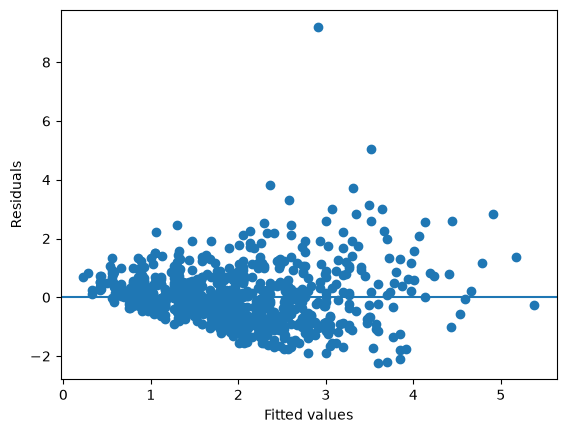

Lower half SD: 0.5909630790937085
Upper half SD: 1.2325272397336524
Ratio: 2.0856247764646083


In [19]:
fitted = fit.fittedvalues
residuals = fit.resid

plt.scatter(fitted, residuals)
plt.axhline(0)
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.show()

middle = fitted.median()

lower = residuals[fitted <= middle]
upper = residuals[fitted > middle]

print("Lower half SD:", lower.std())
print("Upper half SD:", upper.std())
print("Ratio:", upper.std() / lower.std())

The residuals have greater spread at higher fitted values, with the upper-half standard deviation about 2.09 times the lower-half standard deviation. This suggests heteroskedasticity, meaning the error variance is not constant. Consequently, the usual standard errors, confidence intervals, and hypothesis tests from the linear model may be unreliable, so the model may need a transformation or another approach to handle the unequal variance.


### Task 8.  (10 points)

Fit the model again with the log of repair days as the outcome. Report the same spread ratio for the new residuals, say which model you would use and why, and write the sentence that interprets the supplier coefficient on the log scale. A coefficient of $b$ on a logged outcome is roughly a $100(e^{b}-1)%$ change.

Supplier effect (%): -20.23338316656621
95% CI for supplier effect (%): (np.float64(-25.22821893884507), np.float64(-14.90488696734592))


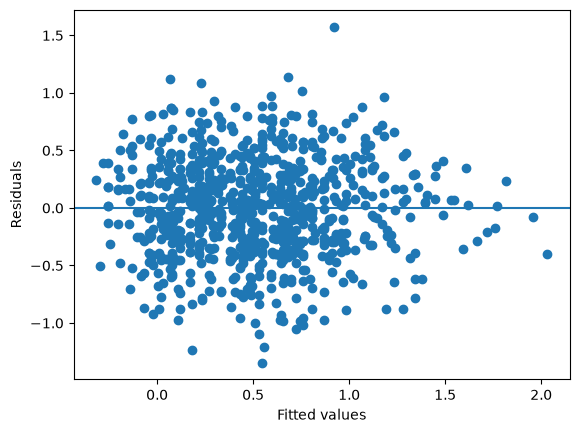

Spread ratio: 1.0983907496103575
Supplier coefficient: -0.2260651044796308
95% CI: [-0.29072963072827535, -0.16140057823098625]


In [20]:
fit_log = smf.ols(
    "np.log(days) ~ new_supplier + parts_needed + tech_years + C(bike_type)",
    data=repairs
).fit()

b = fit_log.params["new_supplier"]
ci = fit_log.conf_int().loc["new_supplier"]

print("Supplier effect (%):", 100 * (np.exp(b) - 1))
print("95% CI for supplier effect (%):",
      (100 * (np.exp(ci.iloc[0]) - 1),
       100 * (np.exp(ci.iloc[1]) - 1)))

fitted_log = fit_log.fittedvalues
residuals_log = fit_log.resid

plt.scatter(fitted_log, residuals_log)
plt.axhline(0)
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.show()

middle_log = fitted_log.median()
lower_log = residuals_log[fitted_log <= middle_log]
upper_log = residuals_log[fitted_log > middle_log]

print("Spread ratio:", upper_log.std() / lower_log.std())
print("Supplier coefficient:", fit_log.params["new_supplier"])
print("95% CI:", fit_log.conf_int().loc["new_supplier"].tolist())

The log model has a residual spread ratio of 1.10, much closer to 1 than the original model's ratio of 2.09, so I would choose the log model because it better addresses the unequal residual variance. Holding the other predictors constant, the new supplier is associated with approximately 20.2% shorter repair times, with a 95% confidence interval for the log coefficient of (−0.291, −0.161). Transforming the coefficient interval to percentages gives an estimated reduction of about 20.2% in repair time, with a 95% confidence interval from a 14.9% to a 25.2% reduction.


### Task 9.  (8 points)

Fit a model for log repair days that starts with every predictor the shop records. Then cut it down to the columns that are carrying their weight, using a method from this course. Say which method you used, report what it kept and what it dropped, and say in two or three sentences whether the result changes anything about your answer to Task 4.

In [21]:
terms = [
    "parts_needed", "parts_cost", "tech_years",
    "C(bike_type)", "new_supplier", "ticket_number",
    "shop_rating", "C(quarter)"
]

full_log = smf.ols(
    "np.log(days) ~ " + " + ".join(terms),
    data=repairs
).fit()

current = full_log
dropped = []

while True:
    choices = []

    for term in terms:
        remaining = [x for x in terms if x != term]
        candidate = smf.ols(
            "np.log(days) ~ " + " + ".join(remaining),
            data=repairs
        ).fit()
        choices.append((candidate.aic, term, candidate, remaining))

    best = min(choices, key=lambda x: x[0])

    if best[0] < current.aic:
        current = best[2]
        dropped.append(best[1])
        terms = best[3]
    else:
        break

print("Full model AIC:", round(full_log.aic, 2))
print("Final model AIC:", round(current.aic, 2))
print("Dropped:", dropped)
print("Kept:", terms)
print(current.params.round(3))

Full model AIC: 937.13
Final model AIC: 932.9
Dropped: ['parts_cost', 'shop_rating', 'C(quarter)']
Kept: ['parts_needed', 'tech_years', 'C(bike_type)', 'new_supplier', 'ticket_number']
Intercept                   0.049
C(bike_type)[T.electric]    0.325
C(bike_type)[T.mountain]    0.060
C(bike_type)[T.road]       -0.041
parts_needed                0.212
tech_years                 -0.038
new_supplier               -0.229
ticket_number               0.000
dtype: float64


I used backward selection with AIC, removing one predictor at a time when its removal lowered AIC, from 937.13 to 932.90. The final model kept parts needed, technician experience, bike type, supplier, and ticket number, and dropped parts cost, shop rating, and quarter. The new supplier coefficient remains negative at −0.229 on the log scale, consistent with the adjusted association in Task 4, although the log-scale coefficient describes a percentage change rather than a change in days. Ticket number was retained by AIC, but this does not mean it has a meaningful causal effect on repair time.

### Task 10.  (8 points)

Fit a decision tree for log repair days from parts needed, technician experience, bike type and supplier. Choose its depth with an appropriate method and say why that method works. For this tree, state how many different exact values can be predicted.

In [22]:
X = pd.get_dummies(
    repairs[["parts_needed", "tech_years", "bike_type", "new_supplier"]],
    drop_first=True
)
y = np.log(repairs["days"])

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=0
)

for depth in [1, 2, 4, 6, 8, 10, 12]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, ytr)
    own = np.sqrt(((ytr - tree.predict(Xtr)) ** 2).mean())
    held = np.sqrt(((yte - tree.predict(Xte)) ** 2).mean())
    print(f"depth {depth:>2}   own rows {own:.3f}   held back {held:.3f}")

tree = DecisionTreeRegressor(max_depth=4, random_state=0).fit(Xtr, ytr)
print("Number of terminal leaves:", tree.get_n_leaves())
print(export_text(tree, feature_names=list(X.columns), decimals=2))
print("Number of predicted values:", len(np.unique(tree.predict(X))))

depth  1   own rows 0.502   held back 0.506
depth  2   own rows 0.471   held back 0.489
depth  4   own rows 0.429   held back 0.474
depth  6   own rows 0.393   held back 0.491
depth  8   own rows 0.369   held back 0.490
depth 10   own rows 0.358   held back 0.502
depth 12   own rows 0.358   held back 0.501
Number of terminal leaves: 16
|--- parts_needed <= 4.50
|   |--- parts_needed <= 2.50
|   |   |--- tech_years <= 3.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.26]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.65]
|   |   |--- tech_years >  3.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value: [0.14]
|   |   |   |--- new_supplier >  0.50
|   |   |   |   |--- value: [-0.08]
|   |--- parts_needed >  2.50
|   |   |--- bike_type_electric <= 0.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value: [0.64]
|   |   |   |--- new_supplier >  0.50
|   |   |   |   |--- value: [0.40]
|   |   |--- bike_typ

I chose a tree depth of 4 because it had the lowest held-back RMSE (0.474) among the depths tested, so it performed best on data not used to fit the tree. The tree has 16 terminal leaves, each of which predicts a constant log repair time, giving 16 distinct predicted values.

### Task 11.  (10 points)

Use the regression tree as a guide to recommend at least two new terms to add to the regression model from Task 8 that induce non-linearity. For each new term, check whether it improves the model or not.

In [23]:
fit_quad = smf.ols(
    "np.log(days) ~ new_supplier + parts_needed + tech_years "
    "+ C(bike_type) + I(parts_needed**2)",
    data=repairs
).fit()

fit_interaction = smf.ols(
    "np.log(days) ~ new_supplier + parts_needed + tech_years "
    "+ C(bike_type) + parts_needed:new_supplier",
    data=repairs
).fit()

print("Task 8 AIC:", round(fit_log.aic, 2))

print("\nSquared parts-needed term:")
print(anova_lm(fit_log, fit_quad))
print("AIC:", round(fit_quad.aic, 2))

print("\nParts-needed by supplier interaction:")
print(anova_lm(fit_log, fit_interaction))
print("AIC:", round(fit_interaction.aic, 2))

Task 8 AIC: 933.59

Squared parts-needed term:
   df_resid         ssr  df_diff   ss_diff         F    Pr(>F)
0     793.0  147.853322      0.0       NaN       NaN       NaN
1     792.0  147.653981      1.0  0.199341  1.069243  0.301432
AIC: 934.51

Parts-needed by supplier interaction:
   df_resid         ssr  df_diff   ss_diff         F    Pr(>F)
0     793.0  147.853322      0.0       NaN       NaN       NaN
1     792.0  147.695764      1.0  0.157558  0.844887  0.358283
AIC: 934.74


The tree suggested adding a squared parts-needed term to capture curvature and a parts-needed-by-supplier interaction to allow the supplier effect to vary with job size. The squared term was not statistically significant (\(p=0.301\)) and increased AIC from 933.59 to 934.51, while the interaction was also not significant (\(p=0.358\)) and increased AIC to 934.74. Since neither term improves the model enough to justify the added complexity, I would retain the simpler Task 8 model.

### Task 12.  (6 points)

A customer brings in a commuter bike needing 4 parts, going to a technician with 2 years of experience, with parts from the new supplier. Predict the turnaround from the model you settled on from Task 11, give the interval you would quote them, and say in one sentence why that interval rather than the other.

In [24]:
customer = pd.DataFrame({
    "bike_type": ["commuter"],
    "parts_needed": [4],
    "tech_years": [2],
    "new_supplier": [1]
})

prediction = fit_log.get_prediction(customer).summary_frame()

print("Predicted days:", np.exp(prediction["mean"].iloc[0]))
print("95% prediction interval:",
      np.exp(prediction[["obs_ci_lower", "obs_ci_upper"]]).values)

Predicted days: 1.9052395768835106
95% prediction interval: [[0.8145737 4.4562424]]


The predicted turnaround is approximately 1.91 days, with a 95% prediction interval of 0.81 to 4.46 days. I would quote the prediction interval because it captures uncertainty for an individual customer's repair, whereas a confidence interval estimates the mean turnaround for all comparable repairs.


### Task 13.  (6 points)

Write six to eight sentences to the shop owner. Cover what you found about the supplier, what you found about big jobs, how sure you are of each, and what they can and cannot do with it. Assume they have not taken this course.

The new supplier is associated with shorter repair times after accounting for parts needed, technician experience, and bike type. The log model estimates repairs take about 20% less time with the new supplier, although the raw averages in Task 3 showed little difference. Repairs requiring more parts generally take longer, so job complexity should be considered when estimating turnaround times. The log model also has more consistent residual spread than the original linear model, making it a better choice for these data. However, individual repair times remain uncertain, as shown by the wide prediction interval for a typical commuter repair. I would keep the new supplier for now and continue monitoring repair times as more jobs come in. These results show an association, not definitive proof that the supplier alone causes faster repairs.
